In [ ]:
'''
Stationarity
    Test - using adfuller test

Stationarising a time series 
    1 - Detrending: Using differencing (smaller brother of differentiation)

how to find out m (seasonality) of a time series
    ACF - Auto correlation function: last days impact on current days
    PACF - Partial auto correlation function: last days impact on current days independently, decoupled with spilled over daily correlations(telephone game effect or ice cream example)

ARIMA family of forecasting
    AR - Basically, predicting residuals remaining after de trending and de seasonlising
        Last p (also a parameter in the sarimax model, the first one) decided days are treated as function of t day numbers and then linear regression is done 
        Basically exponential model but weights derive instead of them being exponent
    MA - Predicting past errors and based on thaat  forecasting
        AR and MA both predict residuals. AR predict based on past values, MA predicts based on past errors in forecast
        q is the parameter here (3rd one in sarimax)
    ARMA - combination of both AR and MA
        p and q become parameters here
    ARIMA - ARMA with auto differencing
        here we can input non stationary data as well
        d is the parameter here, which tells the order of differencing
        NOW, WITH 3 PARAMETER, AGAIN YOU CAN USE GRID SEARCH TO OPTIMIZE
    SARIMA - ARIMA WITH SEASONALITY
        with so many paramters, very hard to tune

'''

'\nStationarity\n    Test - using adfuller test\n\nStationarising a time series \n    1 - Detrending: Using differencing (smaller brother of differentiation)\n\nhow to find out m (seasonality) of a time series\n    ACF - Auto correlation function: last days impact on current days\n    PACF - Partial auto correlation function: last days impact on current days independently, decoupled with spilled over daily correlations(telephone game effect or ice cream example)\n\nARIMA family of forecasting\n    AR - Basically, predicting residuals remaining after de trending and de seasonlising\n        Last p (also a parameter in the model) decided days are treated as function of t day numbers and then linear regression is done \n        Basically exponential model but weights derive instead of them being exponent\n\n\n'

# Pre processing

In [38]:
import pandas as pd 
import numpy as np 
import statsmodels.api as sm
from statsmodels.tsa.stattools import pacf
from statsmodels.graphics.tsaplots import plot_acf,plot_pacf
from statsmodels.tsa.statespace.sarimax import SARIMAX
from sklearn.metrics import root_mean_squared_error,mean_absolute_error,mean_absolute_percentage_error
import warnings
warnings.filterwarnings('ignore')
from tqdm import tqdm
import matplotlib.pyplot as plt

In [3]:
df=pd.read_csv(r'C:\Users\Mayank Bhatia\Documents\GitHub\DSML\16_ml_unsupervised_and_recsys\16.4_time_seties_analysis_3\mobilesales.csv')

In [4]:
df['DATE']=pd.to_datetime(df['DATE'],format='%d-%m-%Y',errors='coerce')

In [5]:
df=df.set_index('DATE')

In [6]:
df['Sales_2']=df['Sales'].interpolate(method='linear')
df['Sales_3']=df['Sales_2'].clip(upper=np.quantile(df['Sales_2'],0.98),lower=np.quantile(df['Sales_2'],0.02))

<Axes: xlabel='DATE'>

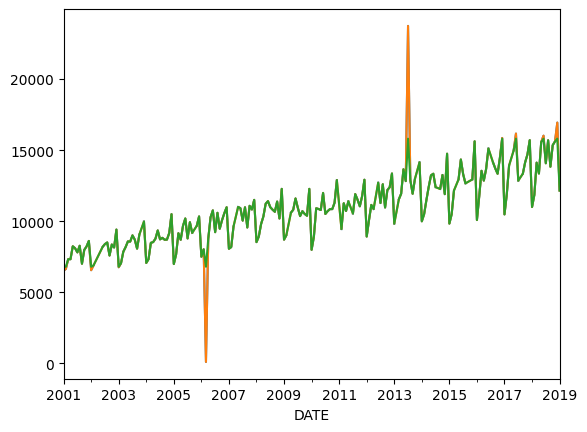

In [7]:
df['Sales'].plot(label='actual')
df['Sales_2'].plot(label='interpolated')
df['Sales_3'].plot(label='clipped')

In [8]:
df_train=df[:-12]
df_test=df[-12:]

# Stationarising a time series

## Differencing (differentiation younger brother)

In [9]:
df['detrend']=df['Sales_3'].diff()

<Axes: xlabel='DATE'>

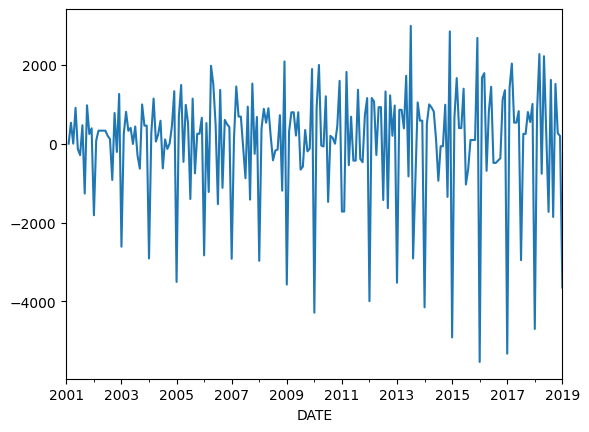

In [10]:
df['detrend'].plot()

In [11]:
sm.tsa.stattools.adfuller(df['detrend'].dropna())[1]

np.float64(1.1781888996319758e-16)

## De seasonlising: m-differencing

In [12]:
df['deseason']=df['detrend'].diff(12)

<Axes: xlabel='DATE'>

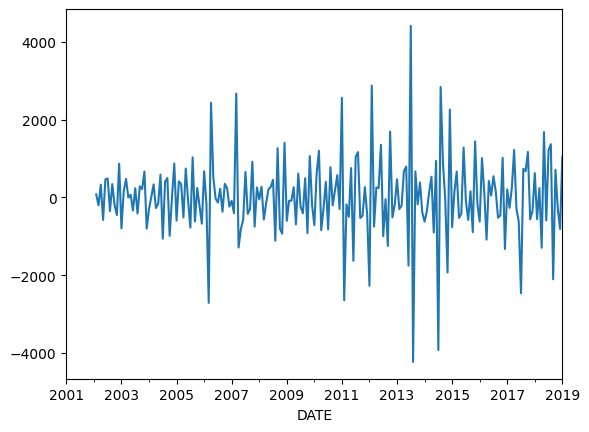

In [13]:
df['deseason'].plot()

In [14]:
sm.tsa.stattools.adfuller(df['deseason'].dropna())[1]

np.float64(1.4566207430682852e-06)

# Finding correct s

## ACF

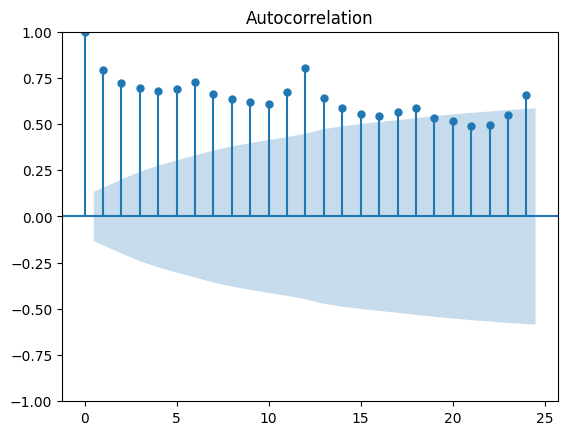

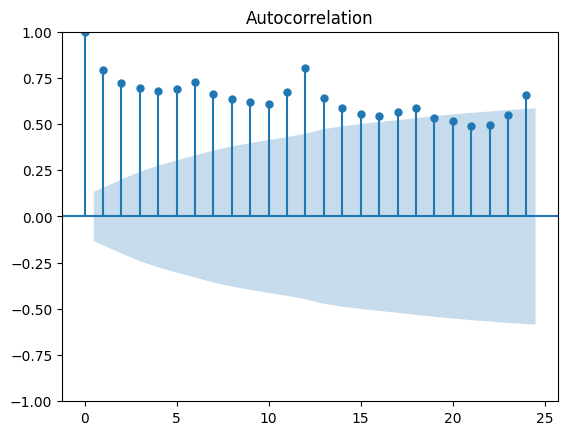

In [15]:
plot_acf(df['Sales_3'])

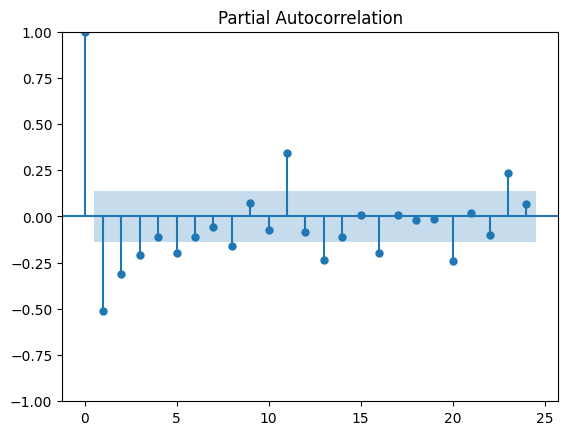

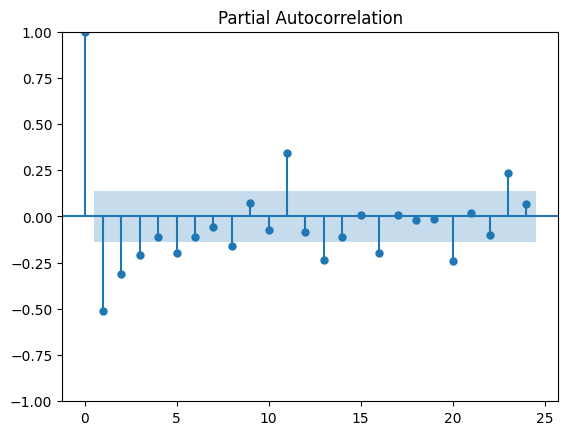

In [16]:
plot_pacf(df['deseason'].dropna())

# Always look for the points outside blue shaded regions

# ARIMA MODELS

## AR - Auto Regressive: only p (last p ddependent values) as parameter

In [17]:
# we only have to de trend and not de seasonalize

df_train_dt=df_train.copy()
df_train_dt['detrend']=df_train_dt['Sales_3'].diff(1)

In [18]:
model=SARIMAX(df_train_dt['detrend'],order=(1,0,0))
model=model.fit()

c:\Users\Mayank Bhatia\AppData\Local\Programs\Python\Python313\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
c:\Users\Mayank Bhatia\AppData\Local\Programs\Python\Python313\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)


In [19]:
df_test['forecasted_residual']=model.forecast(steps=12)

### cumsum acts as integration (reverse of differentiation)

In [20]:
df_test.index

DatetimeIndex(['2018-02-01', '2018-03-01', '2018-04-01', '2018-05-01',
               '2018-06-01', '2018-07-01', '2018-08-01', '2018-09-01',
               '2018-10-01', '2018-11-01', '2018-12-01', '2019-01-01'],
              dtype='datetime64[us]', name='DATE', freq=None)

In [21]:
df_test['prediction_final']=df_test['forecasted_residual'].cumsum() + df_train['Sales_3'].iloc[-1]

<Axes: xlabel='DATE'>

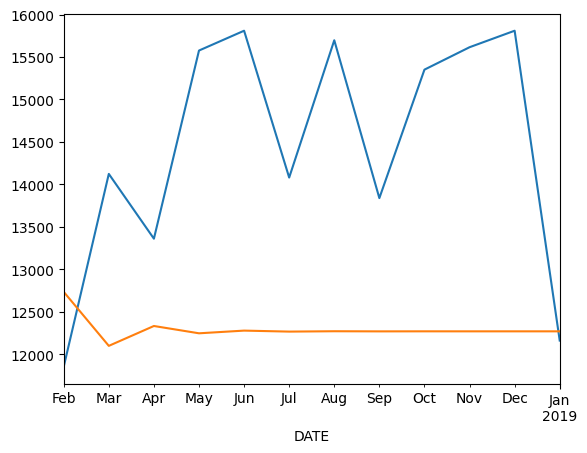

In [22]:
df_test['Sales_3'].plot(label='actual')
df_test['prediction_final'].plot(label='predicted')

In [23]:
print('mape is ',mean_absolute_percentage_error(df_test['Sales_3'],df_test['prediction_final']))

mape is  0.15338220266544755


In [26]:
# lets see mape for different ps

for i in np.arange(2,15):
    model=SARIMAX(df_train_dt['detrend'],order=(i,0,0))
    model=model.fit()

    df_test['pred_res']=model.forecast(steps=12)
    df_test['pred_final']=df_test['pred_res'].cumsum()+df_train_dt['Sales_3'].iloc[-1]

    print ('for i ',i, 'mape is ',mean_absolute_percentage_error(df_test['Sales_3'],df_test['pred_final']))

for i  2 mape is  0.12438384156555854
for i  3 mape is  0.11021643641520439
for i  4 mape is  0.10274642032224575
for i  5 mape is  0.09513525794163159
for i  6 mape is  0.09515395411453266
for i  7 mape is  0.09461924716747887
for i  8 mape is  0.09243088065906942
for i  9 mape is  0.09136994966834124
for i  10 mape is  0.0808685743539313
for i  11 mape is  0.056243458262334185
for i  12 mape is  0.06116888092364329
for i  13 mape is  0.059787149961015036
for i  14 mape is  0.06034810616880142


## MA - Moving Average

In [28]:
# 3rd parameter in sarimax controls the q

model=SARIMAX(df_train_dt['detrend'],order=(0,0,1))
model=model.fit()

df_test['pred_res_ma']=model.forecast(steps=12)
df_test['pred_final_ma']=df_test['pred_res_ma'].cumsum()+df_train['Sales_3'].iloc[-1]

print('mape here is ',mean_absolute_percentage_error(df_test['Sales_3'],df_test['pred_final_ma']))


mape here is  0.093444221182393


<Axes: xlabel='DATE'>

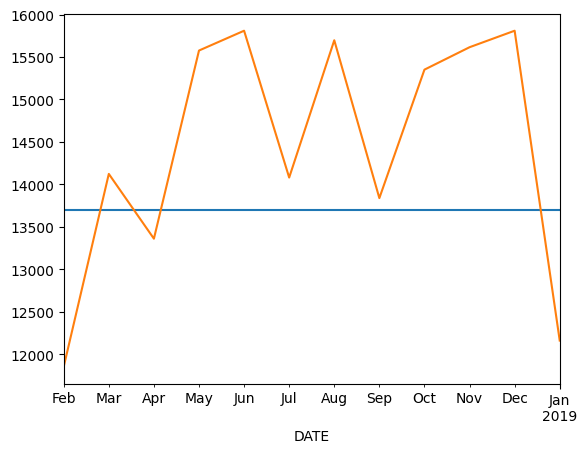

In [31]:
df_test['pred_final_ma'].plot(label='prediction')
df_test['Sales_3'].plot(label='actual')


In [ ]:
for i in np.arange(1,15):
    # 3rd parameter in sarimax controls the q

    model=SARIMAX(df_train_dt['detrend'],order=(0,0,i))
    model=model.fit()

    df_test['pred_res_ma']=model.forecast(steps=12)
    df_test['pred_final_ma']=df_test['pred_res_ma'].cumsum()+df_train['Sales_3'].iloc[-1]

    print('mape here is ',mean_absolute_percentage_error(df_test['Sales_3'],df_test['pred_final_ma']))


mape here is  0.093444221182393
mape here is  0.09213813324037963
mape here is  0.09067563751796409
mape here is  0.0897998521819127
mape here is  0.08779857241687349
mape here is  0.08860107853372039
mape here is  0.09300421780625827
mape here is  0.08415653619217635
mape here is  0.08727698879020217
mape here is  0.10129564574887989
mape here is  0.09015495143587211
mape here is  0.050755703717196794
mape here is  0.07655861003520263
mape here is  0.07543215993019224


## ARMA - combination of both AR and MA

In [44]:
mape=[]
for i in tqdm(np.arange(1,6)):
    for j in tqdm(np.arange(1,6)):
    # 3rd parameter in sarimax controls the q
        model=SARIMAX(df_train_dt['detrend'],order=(i,0,j))
        model=model.fit()

        df_test['pred_res_arma']=model.forecast(steps=12)
        df_test['pred_final_arma']=df_test['pred_res_arma'].cumsum()+df_train['Sales_3'].iloc[-1]

        print('mape for p ',i,'and q ',j,' ',mean_absolute_percentage_error(df_test['Sales_3'],df_test['pred_final_arma']))
        mape.append(mean_absolute_percentage_error(df_test['Sales_3'],df_test['pred_final_arma']))


  0%|          | 0/5 [00:00<?, ?it/s]

mape for p  1 and q  1   0.0931702948349064
mape for p  1 and q  2   0.09151301440332056
mape for p  1 and q  3   0.09210152176436016


mape for p  1 and q  4   0.08730160151338356


 20%|██        | 1/5 [00:01<00:04,  1.11s/it]

mape for p  1 and q  5   0.08863993600374037


...

mape for p  5 and q  2   0.08629187005383188


mape for p  5 and q  3   0.08256510147129661


mape for p  5 and q  4   0.08521996723461094


100%|██████████| 5/5 [00:08<00:00,  1.73s/it]

mape for p  5 and q  5   0.07440391893547513


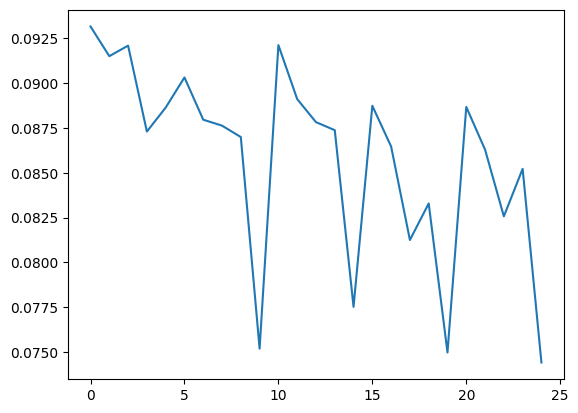

In [ ]:
plt.plot(mape)

<Axes: xlabel='DATE'>

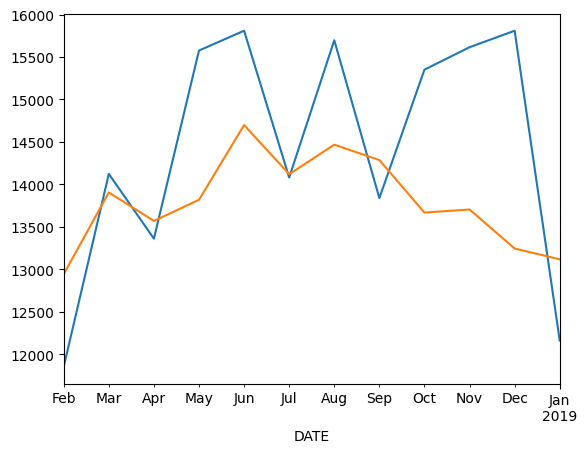

In [40]:
df_test['Sales_3'].plot(label='actual')
df_test['pred_final_ma'].plot(label='pred')

## ARIMA - ARMA WITH DIFFERENCING INTEGRATED

In [ ]:
# Notice that, here we are not using 'detrend' column to train , but directly, sales_3 and it works perfectly
model=SARIMAX(df_train_dt['Sales_3'],order=(3,1,3))
model=model.fit()

df_test['pred_final_arima']=model.forecast(steps=12)


print('mape here is ',mean_absolute_percentage_error(df_test['Sales_3'],df_test['pred_final_arima']))



mape here is  0.08820954301650442


<Axes: xlabel='DATE'>

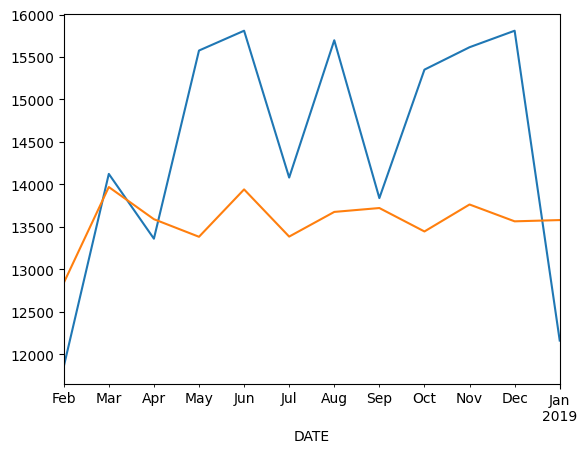

In [ ]:

df_test['Sales_3'].plot(label='actual')
df_test['pred_final_arima'].plot(label='pred')

## SARIMA - ARIMA with seasonality

In [47]:

model=SARIMAX(df_train_dt['Sales_3'],order=(3,1,3),seasonal_order=(1,1,1,12))
model=model.fit()

df_test['pred_final_sarima']=model.forecast(steps=12)


print('mape here is ',mean_absolute_percentage_error(df_test['Sales_3'],df_test['pred_final_sarima']))



mape here is  0.0373052896973523


<Axes: xlabel='DATE'>

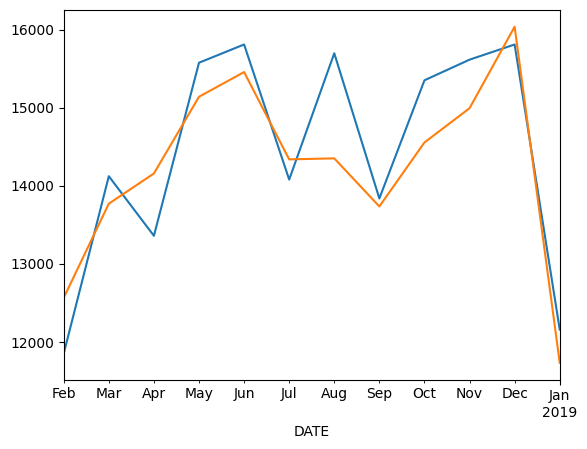

In [48]:
df_test['Sales_3'].plot(label='actual')
df_test['pred_final_sarima'].plot(label='pred')